# Co-occurrence ratios across radii: every cell within the radius is counted

**Author:**
**Jun Inamo**
_Computational Omics and Systems Immunology (COSI) Lab_
_Division of Rheumatology and Center for Health AI_
_University of Colorado School of Medicine, CO, USA_
📧 jun.inamo@cuanschutz.edu

Up to cohalu 0.99.2, `calc_co_occurrence_for_radius()` and the other radius-based functions searched the radius with `RANN::nn2(searchtype = "radius")` and a fixed `k`. That search returns only the `k` nearest cells within the radius, so once a cell had `k` neighbours, a larger radius added nothing and the co-occurrence ratios stopped changing ([issue #1](https://github.com/juninamo/cohalu/issues/1)). The radius search now uses `dbscan::frNN()`, which returns every cell within the radius. A numeric `k` still gives the former capped result.

This notebook checks the new behaviour in three settings.

1. **Cells placed at random.** The co-occurrence ratio should stay close to 1 at every radius, with or without the cap. A radius change by itself must not create a trend.
2. **Simulated tissue domains.** The ratios should keep changing with the radius and match a brute-force count of all cell pairs, while the former cap makes them flat.
3. **10x Xenium data** (human breast and mouse brain). We compare all neighbours with the former cap of `k = 30` and with randomly shuffled labels.

The co-occurrence ratio of types *a* and *b* at radius *r* is the observed number of (*a*, *b*) neighbour pairs within *r*, divided by the number expected from the overall frequencies of *a* and *b* among all pairs within *r*. A value of 1 means no enrichment.

In [1]:
format(Sys.time(), '%d %B, %Y')

[1] "11 November, 2026"

In [2]:
library(ggplot2)
library(dplyr)
library(patchwork)

if (file.exists("../DESCRIPTION")) devtools::load_all("..", quiet = TRUE) else library(cohalu)

# folder with the 10x example datasets (set XENIUM_SAMPLE_DIR to override)
data_dir <- Sys.getenv("XENIUM_SAMPLE_DIR", "./../10X_Xenium_sample")

radii <- seq(10, 300, by = 10)   # µm
options(repr.plot.width = 12, repr.plot.height = 4.6, repr.plot.res = 150)


Attaching package: ‘dplyr’




The following objects are masked from ‘package:stats’:

    filter, lag




The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Loading cohalu v0.99.3: COHALU - CO-localization, Hotspots And sample-Level Units (formerly spatialCooccur).



To cite this package in publications, please use:
  Inamo J, et al. (2026). Spatial transcriptomics reveals  immune-stromal crosstalk within the synovium of patients with  juvenile idiopathic arthritis. JCI Insight. 11(1):e198074.  doi:10.1172/jci.insight.198074



Developed by: Jun Inamo <juninamo@keio.jp>



### Helper functions

`ratio_curves()` runs `calc_co_occurrence_for_radius()` at each radius for each setting of `k` and returns the ratios of every pair of types, together with the number of neighbour pairs that were counted. `k = NULL` (the default) counts every cell within the radius. A numeric `k` reproduces the former behaviour, and the function warns when cells reach the cap, so the warnings are suppressed here.

In [3]:
ratio_curves <- function(seu, radii, settings, cluster_key = "cell_type", sample_key = "sample_id") {
  rows <- list()
  for (r in radii) {
    for (s in names(settings)) {
      res <- suppressWarnings(calc_co_occurrence_for_radius(
        seu, radius = r, sample_key = sample_key, cluster_key = cluster_key, k = settings[[s]]))
      lv <- sub("^Cluster", "", rownames(res$ratio_mat))
      grid <- expand.grid(i = seq_along(lv), j = seq_along(lv))
      rows[[length(rows) + 1]] <- data.frame(
        r = r, setting = s, type_a = lv[grid$i], type_b = lv[grid$j],
        ratio = res$ratio_mat[cbind(grid$i, grid$j)], n_pairs = sum(res$co_occur_count))
    }
  }
  d <- do.call(rbind, rows)
  d$setting <- factor(d$setting, names(settings))
  d$pair <- paste(d$type_a, "×", d$type_b)
  d
}

# share of all neighbour pairs within the radius that each setting counted
pair_share <- function(d, full = names(table(d$setting))[1]) {
  d %>% distinct(r, setting, n_pairs) %>% group_by(r) %>%
    mutate(share = 100 * n_pairs / n_pairs[setting == full]) %>% ungroup()
}

setting_colours <- c("All cells in radius" = "#2a78d6", "k = 100 (former, capped)" = "#1baf7a",
                     "k = 30 (former default)" = "#eb6834", "Shuffled labels" = "#8a8984")
setting_lines <- c("All cells in radius" = "solid", "k = 100 (former, capped)" = "dashed",
                   "k = 30 (former default)" = "dashed", "Shuffled labels" = "dotted")

theme_curves <- function() {
  theme_minimal(base_size = 12) +
    theme(panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = "#e6e5e1", linewidth = 0.4),
          axis.text = element_text(colour = "#52514e"), axis.title = element_text(colour = "#52514e"),
          plot.title = element_text(size = 12, face = "bold"),
          strip.text = element_text(face = "bold", hjust = 0),
          legend.position = "bottom", legend.key.width = unit(2, "lines"))
}

plot_ratios <- function(d, pairs, title, ncol = 3) {
  d %>% filter(pair %in% pairs) %>% mutate(pair = factor(pair, pairs)) %>%
    ggplot(aes(r, ratio, colour = setting, linetype = setting)) +
    geom_hline(yintercept = 1, colour = "#b9b8b3", linewidth = 0.4) +
    geom_line(linewidth = 0.9) +
    facet_wrap(~pair, ncol = ncol, scales = "free_y") +
    scale_colour_manual(values = setting_colours, name = NULL) +
    scale_linetype_manual(values = setting_lines, name = NULL) +
    scale_x_continuous(breaks = seq(0, 300, 100)) +
    labs(title = title, x = "Radius (µm)", y = "Co-occurrence ratio") +
    theme_curves()
}

plot_share <- function(d, title = "Neighbour pairs counted") {
  pair_share(d) %>%
    ggplot(aes(r, share, colour = setting, linetype = setting)) +
    geom_line(linewidth = 0.9) +
    scale_colour_manual(values = setting_colours, name = NULL) +
    scale_linetype_manual(values = setting_lines, name = NULL) +
    scale_x_continuous(breaks = seq(0, 300, 100)) +
    scale_y_continuous(limits = c(0, 100)) +
    labs(title = title, x = "Radius (µm)", y = "% of all pairs within radius") +
    theme_curves() + guides(colour = "none", linetype = "none")
}

## 1. Cells placed at random: no trend with the radius

We place 20,000 cells uniformly at random in a 2,000 × 2,000 µm square (0.005 cells/µm²) and give each cell one of three types at random. There is no spatial structure, so every co-occurrence ratio should be close to 1 at every radius.

In [4]:
set.seed(1)
n <- 20000; side <- 2000
csr <- data.frame(x = runif(n, 0, side), y = runif(n, 0, side),
                  cell_type = sample(c("A", "B", "C"), n, replace = TRUE), sample_id = "random")
seu_csr <- sim_to_seurat(csr)

settings <- list("All cells in radius" = NULL, "k = 30 (former default)" = 30)
d_csr <- ratio_curves(seu_csr, radii, settings)

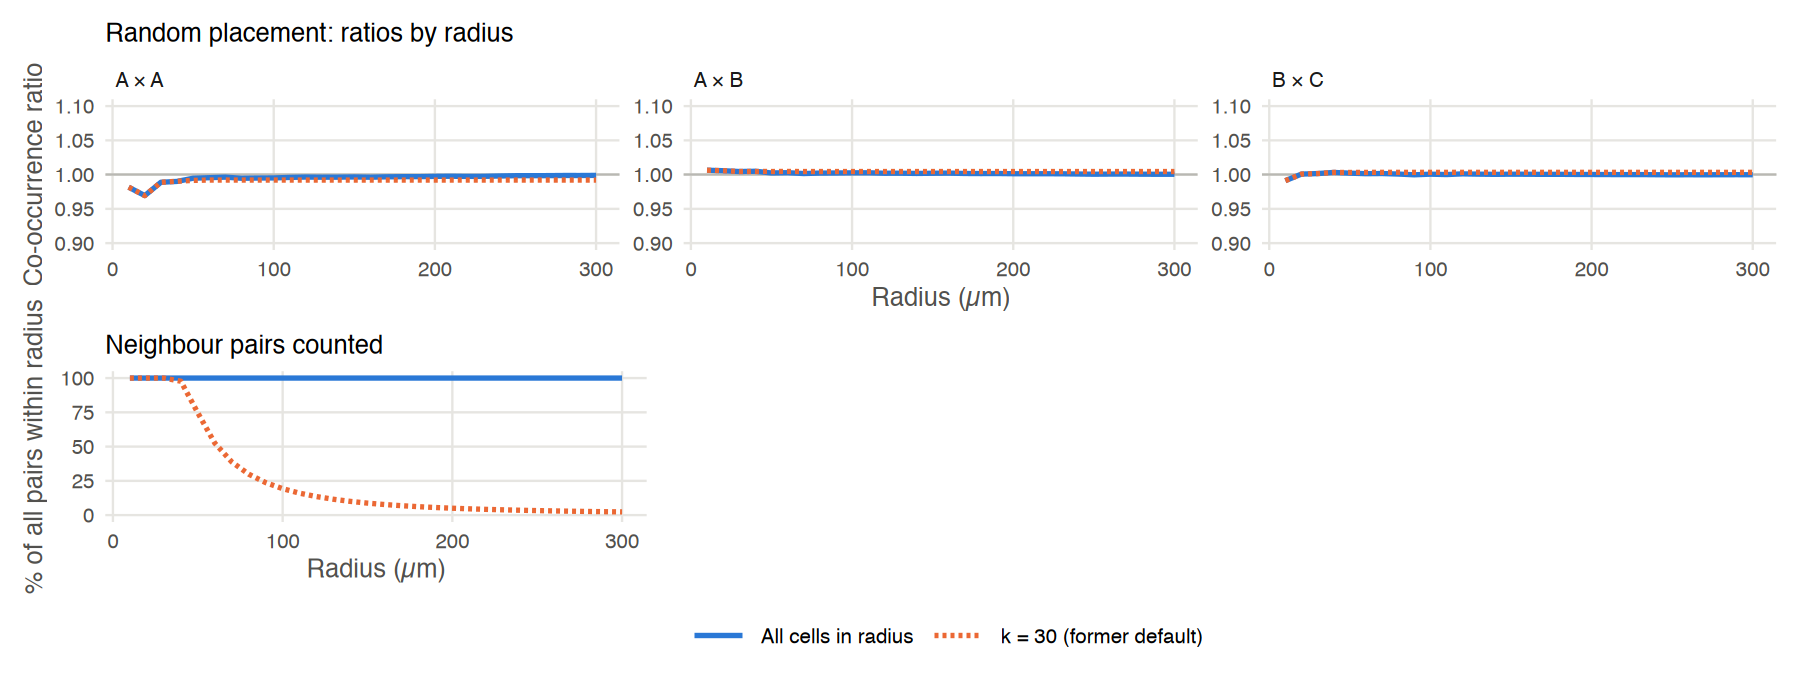

In [5]:
pairs_csr <- c("A × A", "A × B", "B × C")
(plot_ratios(d_csr, pairs_csr, "Random placement: ratios by radius") + coord_cartesian(ylim = c(0.9, 1.1))) /
  (plot_share(d_csr) + plot_spacer() + plot_spacer()) +
  plot_layout(heights = c(1, 1), guides = "collect") & theme(legend.position = "bottom")

In [6]:
# largest distance from 1 for each setting, beyond the smallest radii where few pairs exist
d_csr %>% filter(r >= 30) %>% group_by(setting) %>%
  summarise(max_abs_deviation_from_1 = max(abs(ratio - 1)), .groups = "drop")

setting,max_abs_deviation_from_1
<fct>,<dbl>
All cells in radius,0.01118854
k = 30 (former default),0.01118427


With every cell in the radius counted, the ratios stay within about 0.01 of 1 from 30 µm upwards, and they fluctuate less as the radius grows because more pairs are counted. Without spatial structure there is nothing for the cap to distort, so the capped search also gives ratios near 1. But beyond about 40 µm it counts a shrinking share of the pairs (lower panel): 20% at 100 µm and 2% at 300 µm.

## 2. Simulated tissue domains: ratios follow the structure at every radius

Next we add structure. Around 11 random centres, cells within 300 µm are mostly A or B (45% each, 10% C); elsewhere they are mostly C (80%). A and B therefore share domains and are enriched next to each other, while A and C are segregated. As the radius grows towards and beyond the domain size, neighbourhoods reach outside the domains and both ratios should move towards 1.

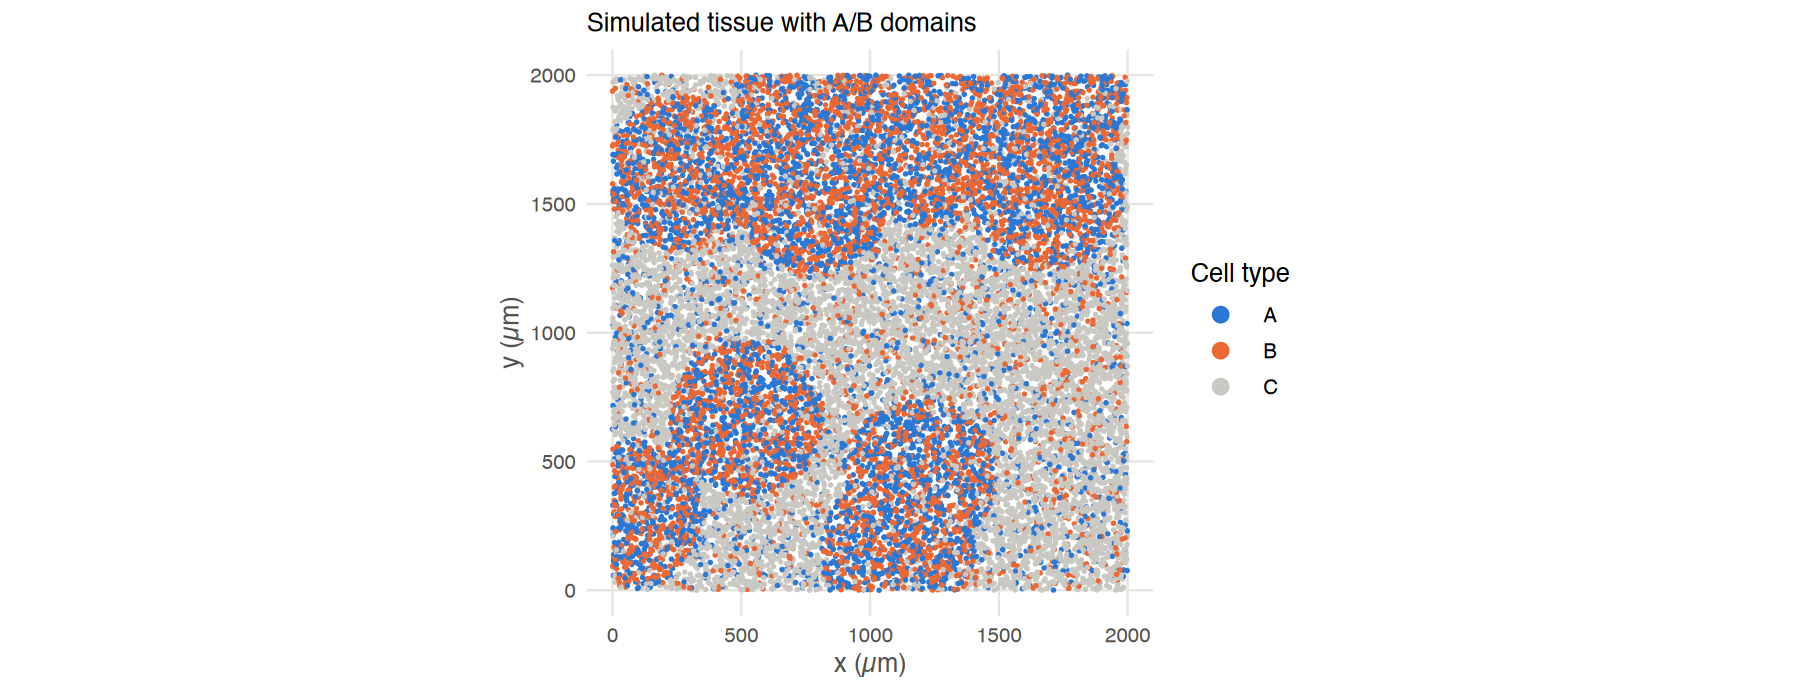

In [7]:
set.seed(1)
xy <- cbind(x = runif(n, 0, side), y = runif(n, 0, side))
centres <- cbind(runif(11, 0, side), runif(11, 0, side))
in_domain <- RANN::nn2(centres, xy, k = 1)$nn.dists[, 1] < 300
cell_type <- ifelse(in_domain,
                    sample(c("A", "B", "C"), n, TRUE, c(0.45, 0.45, 0.10)),
                    sample(c("A", "B", "C"), n, TRUE, c(0.10, 0.10, 0.80)))
dom <- data.frame(xy, cell_type = cell_type, sample_id = "domains")
seu_dom <- sim_to_seurat(dom)

ggplot(dom, aes(x, y, colour = cell_type)) +
  geom_point(size = 0.25) + coord_equal() +
  scale_colour_manual(values = c(A = "#2a78d6", B = "#eb6834", C = "#c9c8c3"), name = "Cell type") +
  guides(colour = guide_legend(override.aes = list(size = 3))) +
  labs(title = "Simulated tissue with A/B domains", x = "x (µm)", y = "y (µm)") +
  theme_curves() + theme(legend.position = "right")

In [8]:
settings <- list("All cells in radius" = NULL, "k = 100 (former, capped)" = 100, "k = 30 (former default)" = 30)
d_dom <- ratio_curves(seu_dom, radii, settings)

To check the counts independently of any neighbour search, we compute all pairwise distances in blocks and count every pair within the radius directly.

In [9]:
brute_ratio <- function(xy, labels, radii, block = 500) {
  lv <- sort(unique(labels)); f <- match(labels, lv); L <- length(lv)
  counts <- setNames(lapply(radii, function(r) matrix(0, L, L, dimnames = list(lv, lv))), radii)
  for (q in split(seq_len(nrow(xy)), ceiling(seq_len(nrow(xy)) / block))) {
    d2 <- outer(xy[q, 1], xy[, 1], "-")^2 + outer(xy[q, 2], xy[, 2], "-")^2
    d2[cbind(seq_along(q), q)] <- Inf   # a cell is not its own neighbour
    for (r in radii) {
      w <- which(d2 <= r^2, arr.ind = TRUE)
      key <- as.character(r)
      counts[[key]] <- counts[[key]] + unclass(table(factor(f[q][w[, 1]], 1:L), factor(f[w[, 2]], 1:L)))
    }
  }
  do.call(rbind, lapply(radii, function(r) {
    R <- compute_co_occurrence_ratio(counts[[as.character(r)]])
    data.frame(r = r, pair = c("A × B", "A × C"), ratio = c(R["A", "B"], R["A", "C"]))
  }))
}

check_radii <- c(50, 150, 300)
brute <- brute_ratio(xy, cell_type, check_radii)

d_dom %>% filter(setting == "All cells in radius", r %in% check_radii, pair %in% c("A × B", "A × C")) %>%
  select(r, pair, ratio_cohalu = ratio) %>%
  inner_join(rename(brute, ratio_brute_force = ratio), by = c("r", "pair")) %>%
  mutate(difference = ratio_cohalu - ratio_brute_force)

r,pair,ratio_cohalu,ratio_brute_force,difference
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
50,A × B,1.3331583,1.3331583,0
50,A × C,0.5517648,0.5517648,0
150,A × B,1.2809390,1.2809390,0
150,A × C,0.6267918,0.6267918,0
300,A × B,1.2062173,1.2062173,0
300,A × C,0.7251683,0.7251683,0


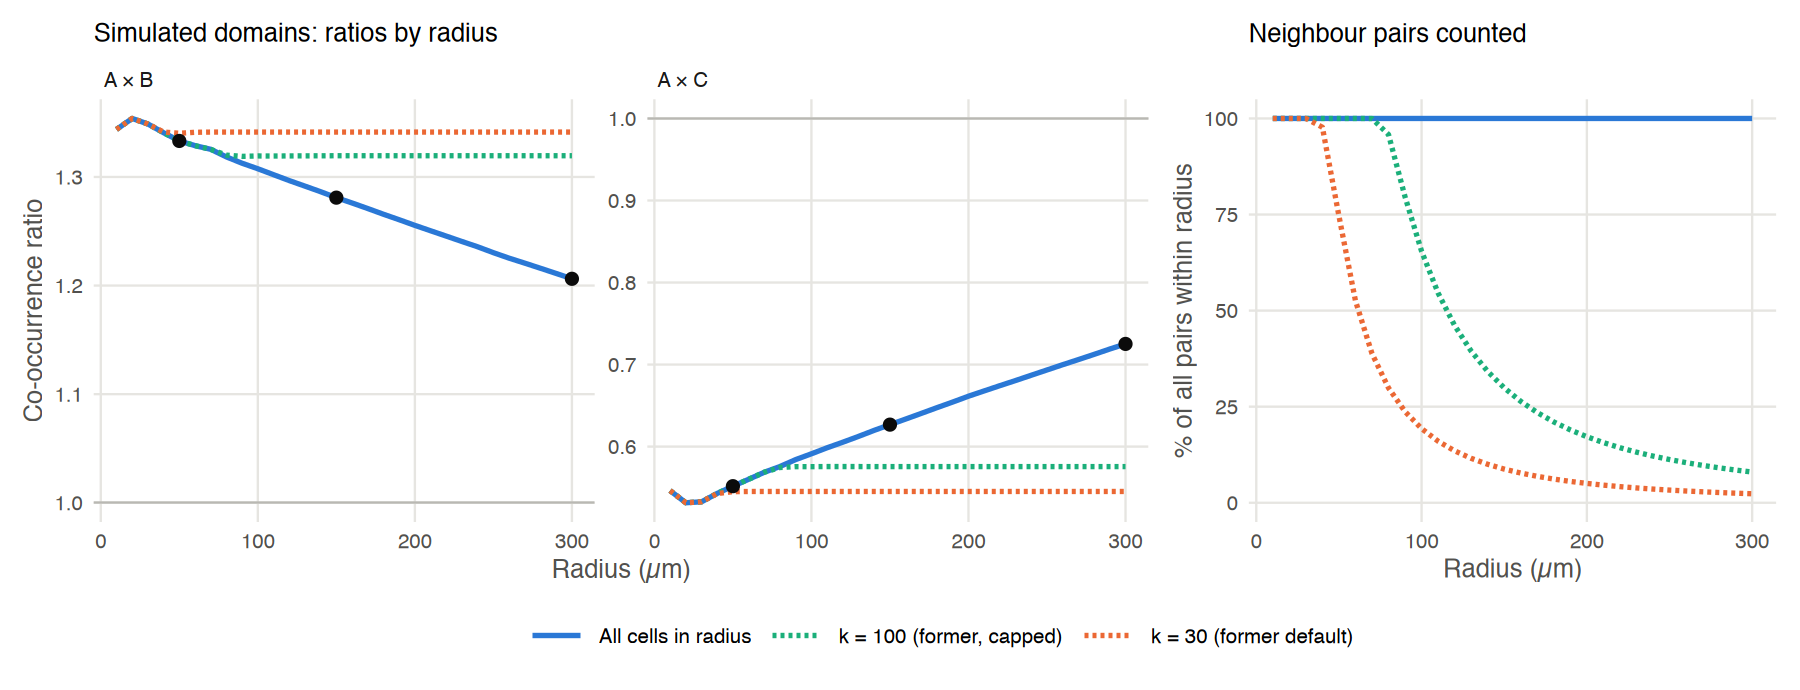

In [10]:
options(repr.plot.height = 4.6)
(plot_ratios(d_dom, c("A × B", "A × C"), "Simulated domains: ratios by radius", ncol = 2) +
   geom_point(data = brute %>% mutate(setting = factor("All cells in radius", names(settings))),
              colour = "#0b0b0b", size = 2.2, show.legend = FALSE)) +
  plot_share(d_dom) +
  plot_layout(widths = c(2, 1), guides = "collect") & theme(legend.position = "bottom")

The black points are the brute-force counts, and they lie on the curve for all cells in the radius (the table above shows the differences are zero up to rounding). That curve changes smoothly over the whole range: A–B falls from about 1.35 towards 1 and A–C rises from about 0.55 towards 1 as the neighbourhoods extend past the domains. With the former cap, each curve stops changing once most cells have reached `k` neighbours, at about 40–50 µm for `k = 30` and 80–90 µm for `k = 100`, and the share of pairs counted falls well below 100%.

## 3. 10x Xenium data

We use two public 10x Xenium datasets, also used in the [10x Xenium tutorial](SNA_tutorial_10Xdata.html): human breast (2 FOVs) and mouse brain (coronal subset). To keep this notebook light and reproducible, the cell types are the graph-based clusters that the Xenium pipeline writes to `analysis/`, each named after its most up-regulated gene. Cell positions are the cell centroids in `cells.csv.gz`.

For each dataset we compare three settings:

- **All cells in radius**: the current default.
- **k = 30**: the former default cap.
- **Shuffled labels**: all cells in the radius, after randomly permuting the cluster labels across cells. This removes any spatial association between types while keeping the cell positions, so it shows what the ratios look like without spatial structure at each radius.

In [11]:
load_xenium_clusters <- function(path, sample_id) {
  cells <- read.csv(file.path(path, "cells.csv.gz"))
  analysis <- file.path(path, "analysis")
  if (!dir.exists(analysis)) {   # some outputs ship the analysis folder as a tarball
    exdir <- tempfile()
    untar(file.path(path, "analysis.tar.gz"), exdir = exdir)
    analysis <- file.path(exdir, "analysis")
  }
  cl <- read.csv(file.path(analysis, "clustering/gene_expression_graphclust/clusters.csv"))
  de <- read.csv(file.path(analysis, "diffexp/gene_expression_graphclust/differential_expression.csv"),
                 check.names = FALSE)
  ids <- sort(unique(cl$Cluster))
  # name each cluster after its most up-regulated gene among significant genes
  top_gene <- vapply(ids, function(i) {
    fc <- de[[paste("Cluster", i, "Log2 fold change")]]
    fc[de[[paste("Cluster", i, "Adjusted p value")]] >= 0.05] <- -Inf
    de[["Feature Name"]][which.max(fc)]
  }, character(1))
  label <- paste0("C", ids, " ", top_gene)
  cells <- cells[match(cl$Barcode, cells$cell_id), ]
  df <- data.frame(x = cells$x_centroid, y = cells$y_centroid,
                   cell_type = factor(label[match(cl$Cluster, ids)], label),
                   sample_id = sample_id, row.names = cells$cell_id)
  df
}

# the most enriched and the most depleted pairs at 30 µm, among clusters with >= min_cells cells;
# pairs that never co-occur (ratio near 0) are left out because they stay at 0 in every setting
top_pairs <- function(d, df, n_each = 3, min_cells = 200, at = 30) {
  keep <- names(which(table(df$cell_type) >= min_cells))
  lv <- levels(df$cell_type)
  cand <- d %>% filter(setting == "All cells in radius", r == at, type_a %in% keep, type_b %in% keep,
                       match(type_a, lv) < match(type_b, lv), ratio > 0.05)
  c(cand %>% arrange(desc(ratio)) %>% head(n_each) %>% pull(pair),
    cand %>% arrange(ratio) %>% head(n_each) %>% pull(pair))
}

xenium_curves <- function(df, seed = 1) {
  seu <- sim_to_seurat(df)
  d <- ratio_curves(seu, radii, list("All cells in radius" = NULL, "k = 30 (former default)" = 30))
  set.seed(seed)
  shuffled <- df; shuffled$cell_type <- sample(shuffled$cell_type)
  d_null <- ratio_curves(sim_to_seurat(shuffled), radii, list("Shuffled labels" = NULL))
  d <- rbind(d, d_null)
  d$setting <- factor(d$setting, c("All cells in radius", "k = 30 (former default)", "Shuffled labels"))
  d
}

### Human breast


 C1 TUBB2B  C2 ABCC11   C3 CENPF    C4 UCP1 C5 CLEC14A   C6 ITGAX C7 S100A14 
      1471       1415       1206       1132        672        547        401 
   C8 KRT5    C9 GZMA 
       246        183 

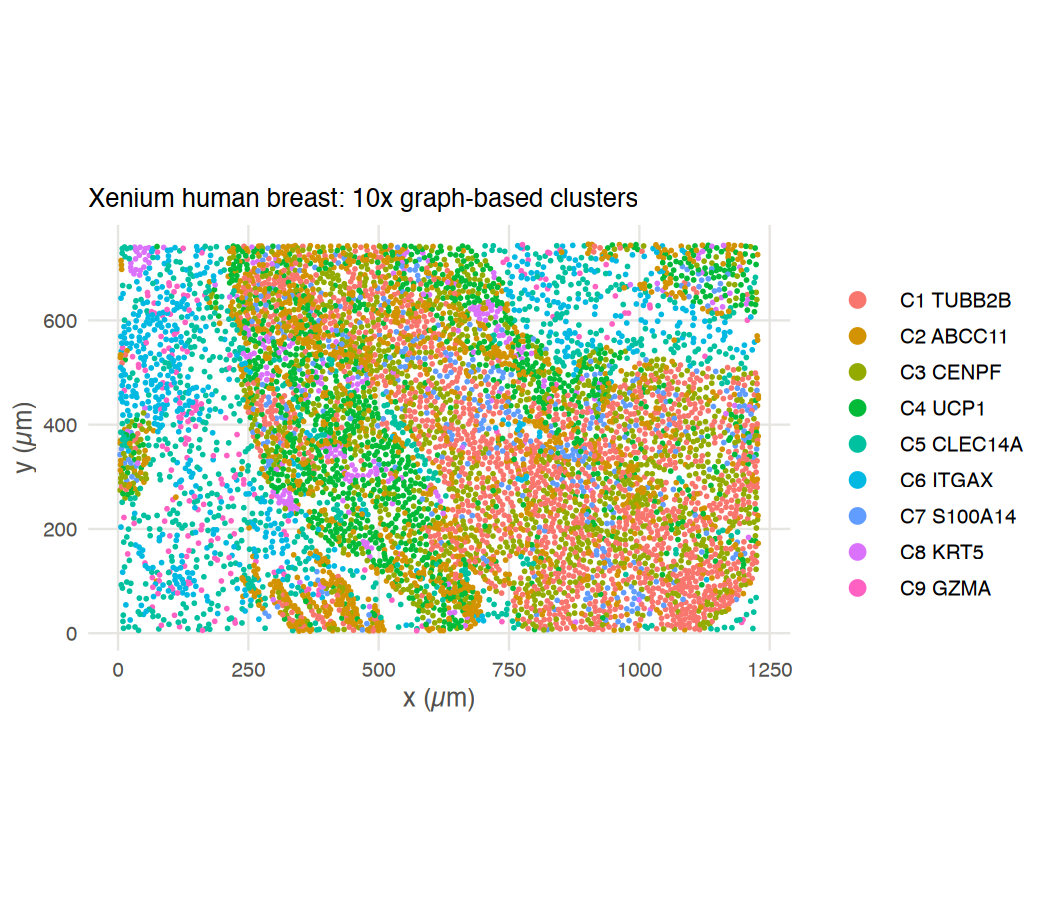

In [12]:
breast <- load_xenium_clusters(file.path(data_dir, "Xenium_V1_human_Breast_2fov_outs"), "breast")
table(breast$cell_type)

options(repr.plot.width = 7, repr.plot.height = 6)
ggplot(breast, aes(x, y, colour = cell_type)) +
  geom_point(size = 0.3) + coord_equal() +
  guides(colour = guide_legend(override.aes = list(size = 3))) +
  labs(title = "Xenium human breast: 10x graph-based clusters", x = "x (µm)", y = "y (µm)", colour = NULL) +
  theme_curves() + theme(legend.position = "right")

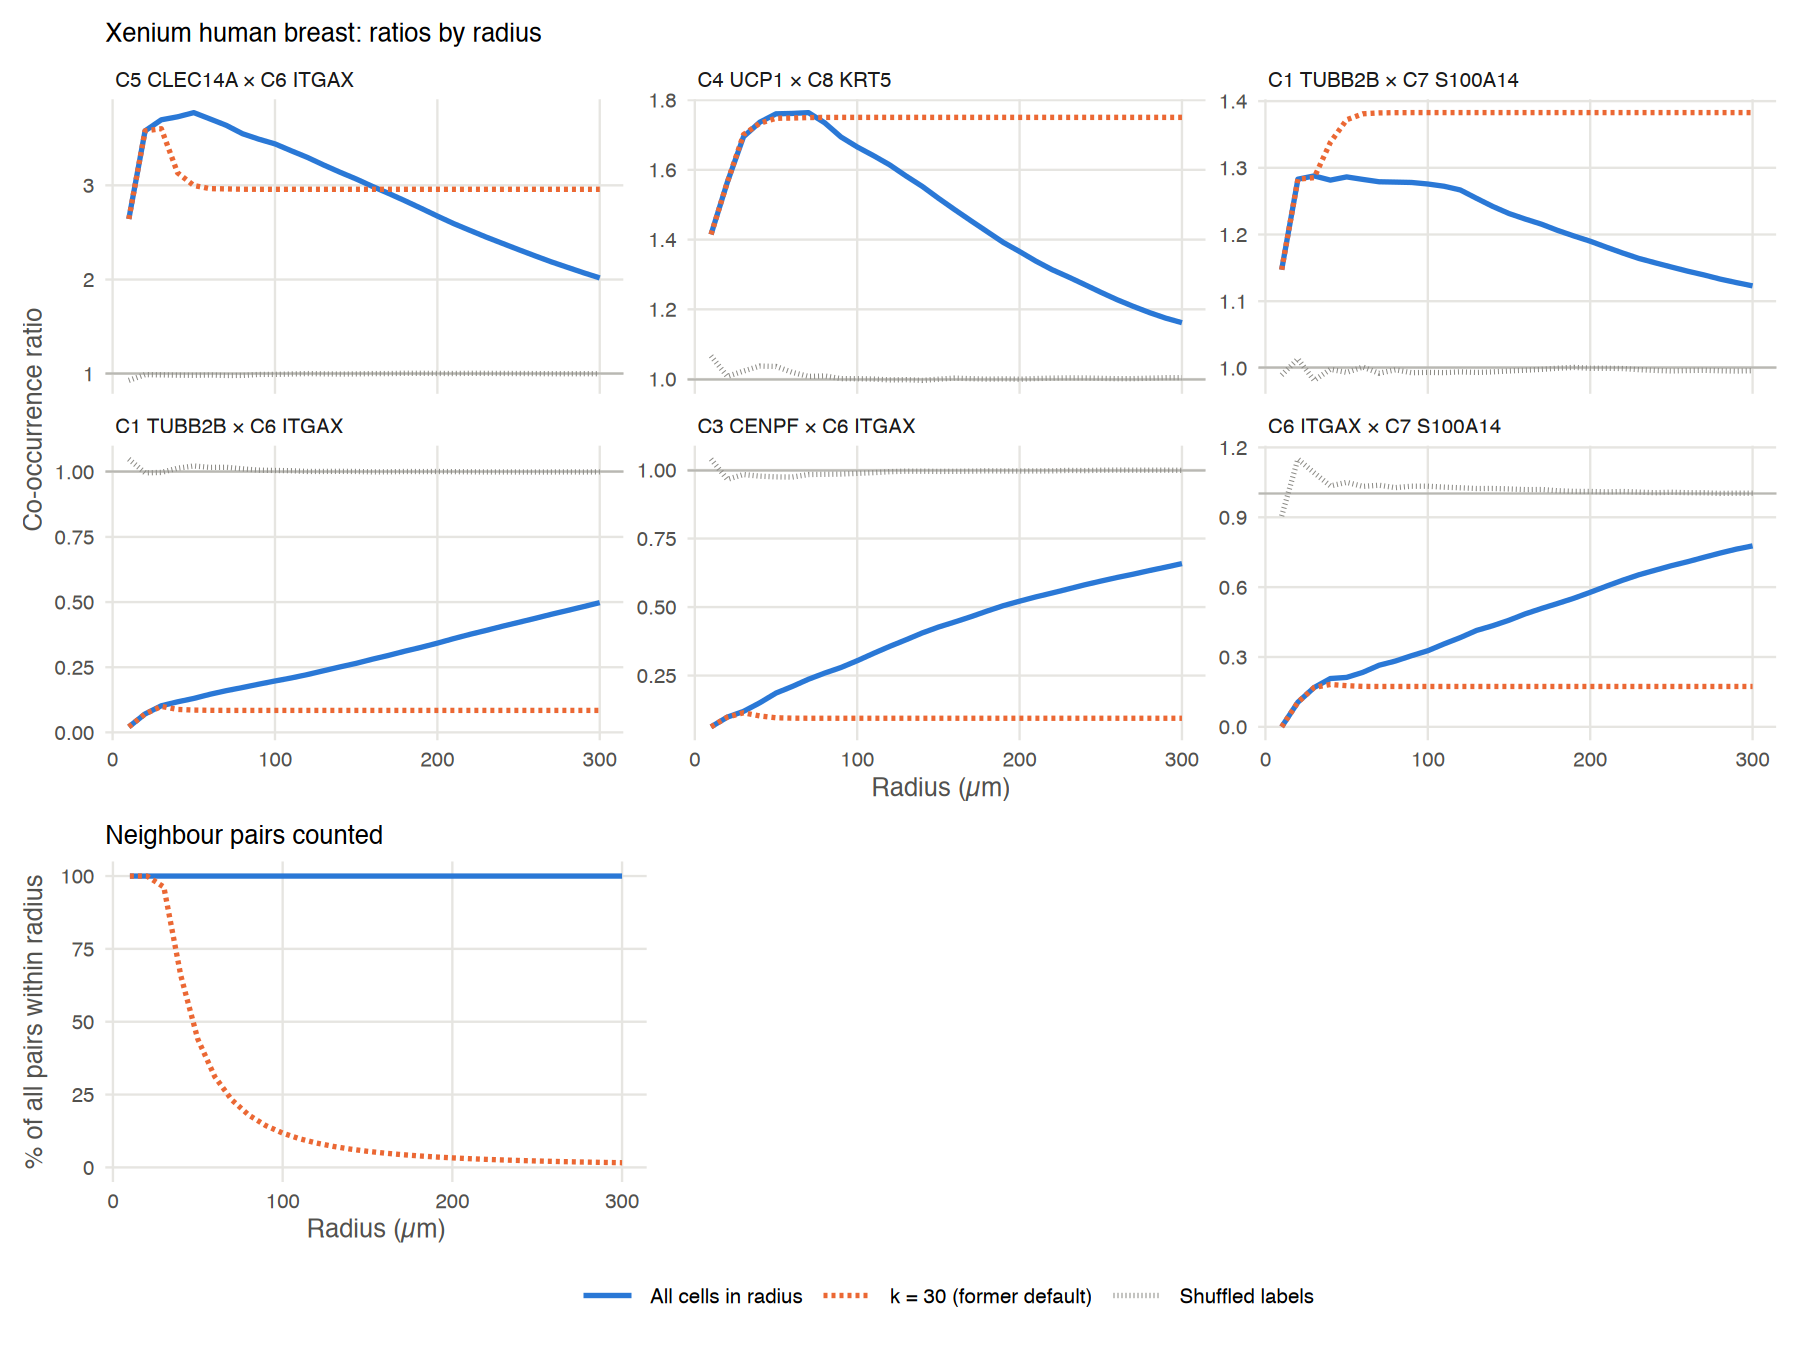

In [13]:
d_breast <- xenium_curves(breast)
pairs_breast <- top_pairs(d_breast, breast)

options(repr.plot.width = 12, repr.plot.height = 9)
plot_ratios(d_breast, pairs_breast, "Xenium human breast: ratios by radius") /
  (plot_share(filter(d_breast, setting != "Shuffled labels")) + plot_spacer() + plot_spacer()) +
  plot_layout(heights = c(2, 1), guides = "collect") & theme(legend.position = "bottom")

In the breast section, the top row shows the three most enriched pairs and the bottom row the three most depleted pairs. With all cells counted, the enriched pairs peak at 30–70 µm and then fall towards 1, and the depleted pairs rise steadily towards 1, as the neighbourhoods grow to include other parts of the section. With the cap, every curve stops changing at about 30–50 µm. A pair that is depleted only locally then looks equally depleted at every scale, and some enriched pairs even keep a higher ratio than at short range (for example C1 × C7: 1.38 with the cap, against 1.12 with all cells at 300 µm). With shuffled labels, the ratios stay near 1 at every radius.

### Mouse brain


   C1 Cldn5   C2 Opalin    C3 Gsg1l     C4 Rprm     C5 Gli3    C6 Rxfp1 
       3154        3026        2975        2499        2220        2203 
   C7 Prox1    C8 Rspo1  C9 Aldh1a2   C10 Cbln1   C11 Calb2  C12 Gm2115 
       1934        1646        1483        1435        1324        1279 
   C13 Chat   C14 Cabp7    C15 Igf1     C16 Sst  C17 Spag16 C18 Cd300c2 
       1269        1244        1136        1078         885         715 
   C19 Cd93    C20 Rfx4    C21 Gfap     C22 Nts   C23 Gpr17   C24 Npy2r 
        669         597         594         585         513         466 
  C25 Cplx3 C26 Cd300c2   C27 Cbln1   C28 Chodl 
        456         453         404         311 

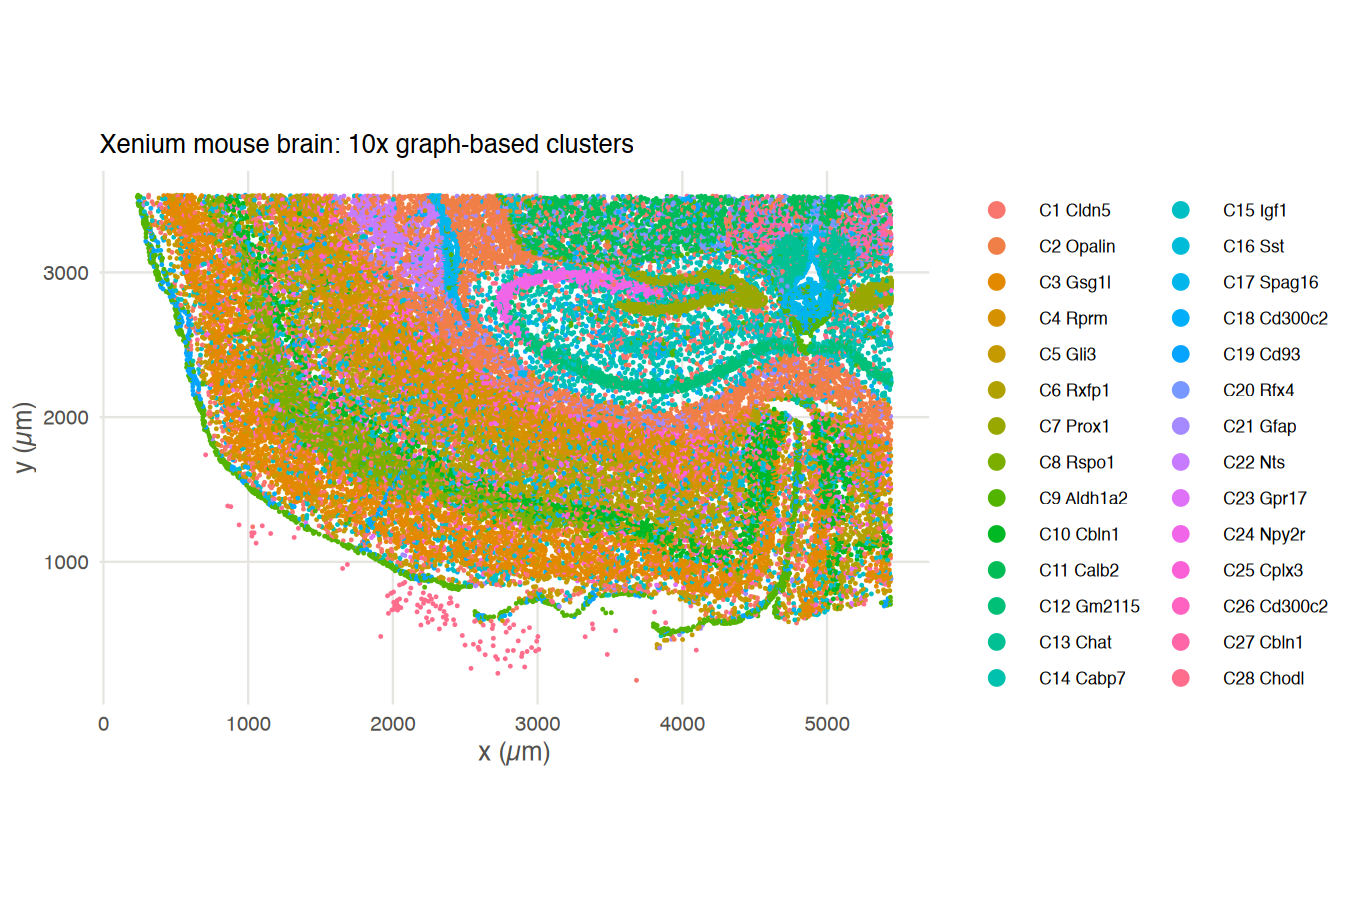

In [14]:
brain <- load_xenium_clusters(file.path(data_dir, "Xenium_V1_FF_Mouse_Brain_Coronal_Subset_CTX_HP_outs"), "brain")
table(brain$cell_type)

options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(brain, aes(x, y, colour = cell_type)) +
  geom_point(size = 0.1) + coord_equal() +
  guides(colour = guide_legend(override.aes = list(size = 3), ncol = 2)) +
  labs(title = "Xenium mouse brain: 10x graph-based clusters", x = "x (µm)", y = "y (µm)", colour = NULL) +
  theme_curves() + theme(legend.position = "right", legend.text = element_text(size = 8))

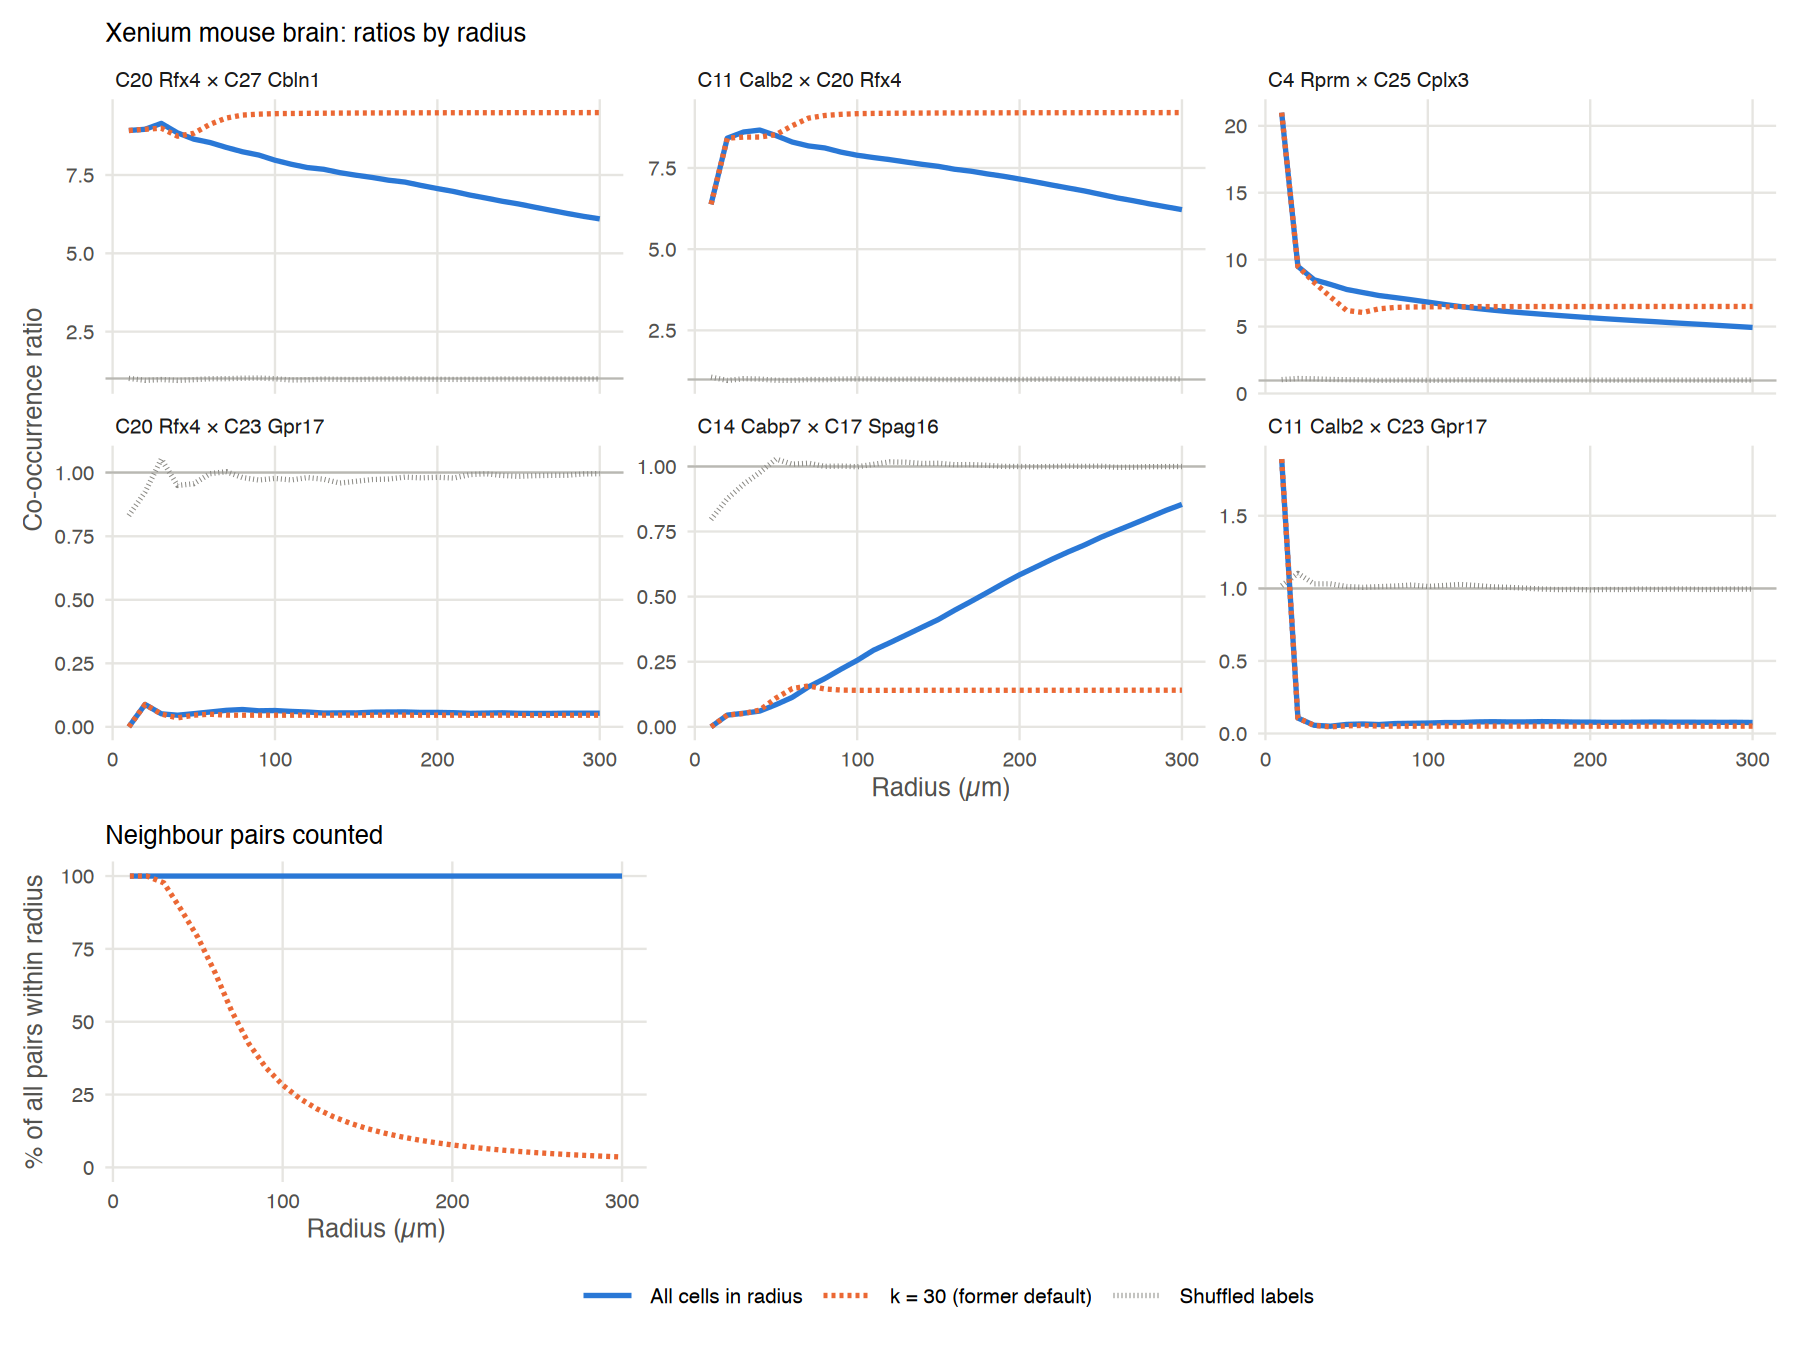

In [15]:
d_brain <- xenium_curves(brain)
pairs_brain <- top_pairs(d_brain, brain)

options(repr.plot.width = 12, repr.plot.height = 9)
plot_ratios(d_brain, pairs_brain, "Xenium mouse brain: ratios by radius") /
  (plot_share(filter(d_brain, setting != "Shuffled labels")) + plot_spacer() + plot_spacer()) +
  plot_layout(heights = c(2, 1), guides = "collect") & theme(legend.position = "bottom")

The mouse brain section is larger and its cell types are arranged in layers and regions, so pairs can stay enriched or depleted over hundreds of micrometres. The capped curves stop changing at about 40–70 µm. They can also move the wrong way: for C20 × C27 and C11 × C20 the uncapped ratio falls from about 9 to about 6 between 30 and 300 µm, while the capped ratio rises slightly and stays above 9.

### How much the cap changed the ratios

For every pair of clusters with at least 200 cells that co-occur at 30 µm (ratio above 0.05), the table compares the former cap of `k = 30` with all cells in the radius at 30, 100 and 300 µm. It gives the share of neighbour pairs the cap counted, and the median and largest absolute log2 ratio between the capped and the uncapped co-occurrence ratio. The last column is the median absolute log2 ratio with shuffled labels, which shows how far ratios move away from 1 without spatial structure.

In [16]:
cap_summary <- function(d, df, name, at = c(30, 100, 300), min_cells = 200) {
  keep <- names(which(table(df$cell_type) >= min_cells))
  lv <- levels(df$cell_type)
  ref <- d %>% filter(setting == "All cells in radius", r == 30, ratio > 0.05,
                      type_a %in% keep, type_b %in% keep, match(type_a, lv) < match(type_b, lv))
  w <- d %>% filter(pair %in% ref$pair, r %in% at) %>%
    select(r, pair, setting, ratio) %>%
    tidyr::pivot_wider(names_from = setting, values_from = ratio)
  lr <- abs(log2(w[["k = 30 (former default)"]] / w[["All cells in radius"]]))
  share <- pair_share(filter(d, setting != "Shuffled labels")) %>%
    filter(setting == "k = 30 (former default)", r %in% at)
  w %>% mutate(abs_log2_cap = lr, abs_log2_shuffled = abs(log2(`Shuffled labels`))) %>%
    group_by(r) %>%
    summarise(n_pairs = n(),
              median_abs_log2_cap_vs_all = median(abs_log2_cap),
              max_abs_log2_cap_vs_all = max(abs_log2_cap),
              median_abs_log2_shuffled = median(abs_log2_shuffled), .groups = "drop") %>%
    left_join(select(share, r, pct_pairs_counted_by_k30 = share), by = "r") %>%
    mutate(dataset = name, .before = 1) %>%
    as.data.frame()
}
rbind(cap_summary(d_breast, breast, "breast"), cap_summary(d_brain, brain, "brain"))

dataset,r,n_pairs,median_abs_log2_cap_vs_all,max_abs_log2_cap_vs_all,median_abs_log2_shuffled,pct_pairs_counted_by_k30
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
breast,30,28,0.01036775,0.06471864,0.017329426,96.220446
breast,100,28,0.23205102,1.68973065,0.005450585,11.769121
breast,300,28,0.59076562,2.80394927,0.001401061,1.607849
brain,30,250,0.03024980,0.14971000,0.059576723,97.646268
brain,100,250,0.26760447,3.58245166,0.017192202,28.275472
brain,300,250,0.39951950,4.53635342,0.005370495,3.570315


At 30 µm, the cap counted 96–98% of the neighbour pairs, and the ratios changed by a median of 1–2% (|log2| of 0.01–0.03). This is why the tutorials, which use 30 µm, change very little. At 100 µm, the cap counted only 12–28% of the pairs, and the median ratio was off by about 17–20% (|log2| of about 0.25), with some pairs off by a factor of 3 or more. At 300 µm, the cap counted 2–4% of the pairs. With shuffled labels, the median ratio stays within a few percent of 1 at every radius.

## Summary

- **No spurious trend.** When there is no spatial structure, both in simulated random placement and in Xenium data with shuffled labels, the ratios stay close to 1 at every radius. A larger radius alone does not change the ratios.
- **Exact counts.** In the simulation, the ratios from `calc_co_occurrence_for_radius()` match a brute-force count of all pairs within the radius.
- **The ratios follow the tissue.** With all neighbours counted, the ratios keep changing as long as the neighbourhood composition changes, and they move towards 1 once the radius is much larger than the structures in the tissue. With the former cap of `k = 30`, the curves flatten at the radius where cells reach 30 neighbours, which is about 30–70 µm in these datasets. Beyond that, the capped ratios can be far from the true ones, and in the mouse brain some even move in the opposite direction.
- **Small radii are unchanged.** Where no cell has more than `k` neighbours, the capped and uncapped results are identical, so analyses at small radii, such as the 30 µm used in the tutorials, change little or not at all.

To reproduce a result computed with cohalu 0.99.2 or earlier, pass the former cap explicitly, for example `calc_co_occurrence_for_radius(..., k = 30)` or `cooccur_ratio_per_sample(..., k = 30)`.

In [17]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: aarch64-apple-darwin20 (64-bit)
Running under: macOS 26.3.1

Matrix products: default
BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0

locale:
[1] en_US.UTF-8/en_US.UTF-8/en_US.UTF-8/C/en_US.UTF-8/en_US.UTF-8

time zone: Asia/Tokyo
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] cohalu_0.99.3   testthat_3.2.1  patchwork_1.1.3 dplyr_1.1.4    
[5] ggplot2_3.4.4  

loaded via a namespace (and not attached):
  [1] RColorBrewer_1.1-3     rstudioapi_0.15.0      jsonlite_2.0.0        
  [4] magrittr_2.0.3         spatstat.utils_3.1-2   farver_2.1.1          
  [7] fs_1.6.3               vctrs_0.6.5            ROCR_1.0-11           
 [10] Cairo_1.6-2            memoise_2.0.1          spatstat.explo